# Avaliação do modelo de URLs

Compara quatro formas de decidir se uma URL é golpe:

- **Só regras**: os pesos fixos do `scoring.py` (marca imitada, TLD, IP, HTTPS etc.)
- **Random Forest** e **Regressão logística** treinados com características do domínio
- **Regras + Random Forest**: a combinação usada pelo app

Dados: `data/processed/urls.csv`, gerado por `python -m scripts.coletar_urls --balancear`.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, roc_curve

from scripts.treinar_modelo import LIMIAR, avaliar, carregar

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": "#b8b7b0", "axes.labelcolor": "#3d3d3a", "xtick.color": "#5f5e5a", "ytick.color": "#5f5e5a",
    "font.size": 10,
})
CORES = {"Só regras": "#2a78d6", "Random Forest": "#eb6834", "Regressão logística": "#1baf7a", "Regras + Random Forest": "#eda100"}

df = carregar(RAIZ / "data/processed/urls.csv")
df.groupby("label").size().rename({0: "legítima", 1: "golpe"})

label
legítima    4005
golpe       4005
dtype: int64

## Cuidado com o vazamento

As URLs legítimas vieram da lista Tranco, que só traz o domínio. Então todas são a página inicial com `https`, enquanto a maioria dos golpes tem caminho e parte usa `http`.

In [2]:
sem_esquema = df["url"].str.replace(r"^https?://", "", regex=True)
pd.DataFrame({
    "usa https": df["url"].str.startswith("https").groupby(df["label"]).mean(),
    "tem caminho": sem_esquema.str.contains("/").groupby(df["label"]).mean(),
}).rename(index={0: "legítima", 1: "golpe"}).round(2)

,usa https,tem caminho
label,,
legítima,1.00,0.00
golpe,0.73,0.91


Um modelo treinado com a URL inteira aprenderia "tem caminho, então é golpe" e acertaria quase tudo aqui, mas erraria no mundo real. Por isso:

- o modelo usa **só características do domínio** (tamanho, entropia, dígitos, TLD, marca imitada...), sem esquema e sem caminho;
- o `www.` é ignorado, porque as legítimas nunca têm `www`;
- treino e teste são separados **por domínio** (`GroupShuffleSplit`), então o teste só tem domínios que o modelo nunca viu.

In [3]:
res = avaliar(df)
print(f"Treino: {res['tamanho']['treino']} URLs | Teste: {res['tamanho']['teste']} URLs de {res['tamanho']['dominios_teste']} domínios nunca vistos")
tabela = pd.DataFrame(res["teste"]).T
tabela

Treino: 6063 URLs | Teste: 1947 URLs de 1583 domínios nunca vistos


,acuracia,precisao,recall,f1,auc
Só regras,0.586,0.958,0.166,0.283,0.826
Random Forest,0.759,0.746,0.773,0.760,0.850
Regressão logística,0.756,0.743,0.770,0.757,0.854
Regras + Random Forest,0.772,0.848,0.654,0.739,0.864


## Comparação no conjunto de teste

Limiar de decisão: risco ≥ 40% conta como golpe.

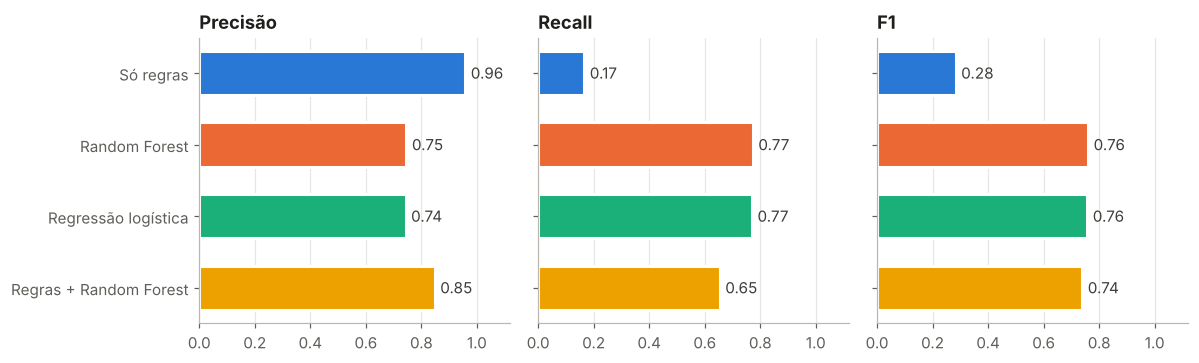

In [4]:
metr = ["precisao", "recall", "f1"]
nomes = {"precisao": "Precisão", "recall": "Recall", "f1": "F1"}
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
for ax, m in zip(axes, metr):
    vals = tabela[m]
    y = np.arange(len(vals))[::-1]
    ax.barh(y, vals, color=[CORES[n] for n in vals.index], height=0.62, edgecolor="white", linewidth=2)
    for yi, v in zip(y, vals):
        ax.text(v + 0.02, yi, f"{v:.2f}", va="center", color="#3d3d3a")
    ax.set_xlim(0, 1.12)
    ax.set_title(nomes[m], loc="left", fontweight="bold", color="#1f1f1d")
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(np.arange(len(tabela))[::-1], tabela.index)
fig.tight_layout()

As regras quase nunca erram quando disparam (precisão alta), mas deixam passar a maioria dos golpes. Boa parte dos golpes do dataset está hospedada em sites `.com.br` comuns que foram invadidos, e nesses o endereço não tem nada de estranho. O modelo pega padrões que as regras não cobrem, como domínios aleatórios e muito longos.

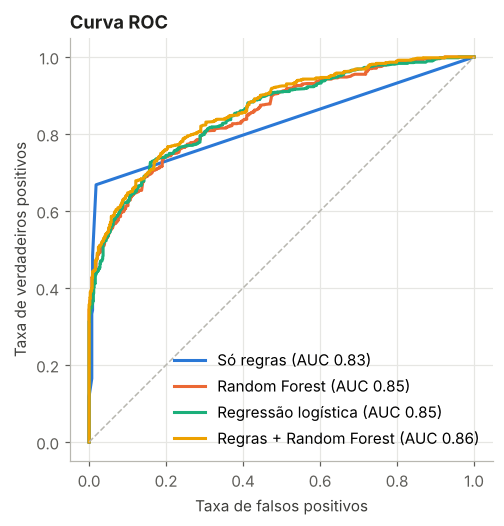

In [5]:
sc = res["scores_teste"]
y = np.array(sc["y"])
fig, ax = plt.subplots(figsize=(5.6, 5))
for nome, cor in CORES.items():
    fpr, tpr, _ = roc_curve(y, sc[nome])
    ax.plot(fpr, tpr, color=cor, linewidth=2, label=f"{nome} (AUC {tabela.loc[nome, 'auc']:.2f})")
ax.plot([0, 1], [0, 1], color="#b8b7b0", linewidth=1, linestyle="--")
ax.set_xlabel("Taxa de falsos positivos")
ax.set_ylabel("Taxa de verdadeiros positivos")
ax.set_title("Curva ROC", loc="left", fontweight="bold", color="#1f1f1d")
ax.legend(frameon=False, loc="lower right")
ax.set_aspect("equal")

## Onde cada abordagem erra

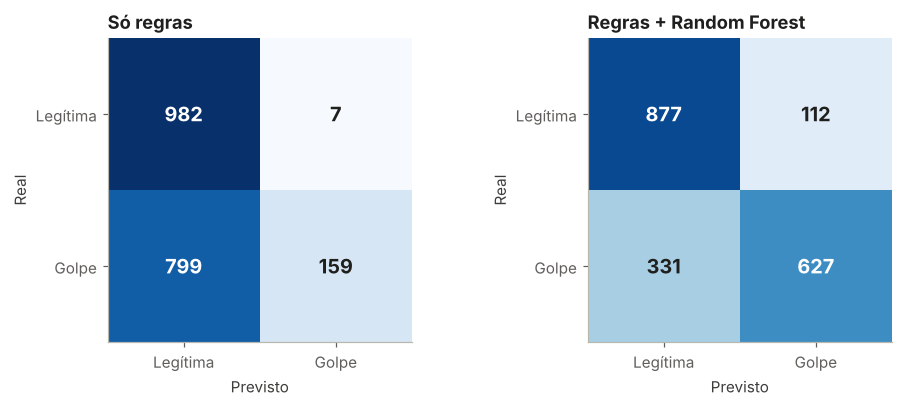

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, nome in zip(axes, ["Só regras", "Regras + Random Forest"]):
    cm = confusion_matrix(y, np.array(sc[nome]) >= LIMIAR)
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=cm.sum() / 2)
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, v, ha="center", va="center", fontsize=13, fontweight="bold",
                color="white" if v > cm.sum() / 4 else "#1f1f1d")
    ax.set_xticks([0, 1], ["Legítima", "Golpe"])
    ax.set_yticks([0, 1], ["Legítima", "Golpe"])
    ax.set_xlabel("Previsto")
    ax.set_ylabel("Real")
    ax.set_title(nome, loc="left", fontweight="bold", color="#1f1f1d")
    ax.grid(False)
fig.tight_layout()

## Quanto peso dar às regras

O app combina `peso × regras + (1 − peso) × modelo`. Mais peso nas regras aumenta a precisão (menos alarme falso em site verdadeiro) e reduz o recall.

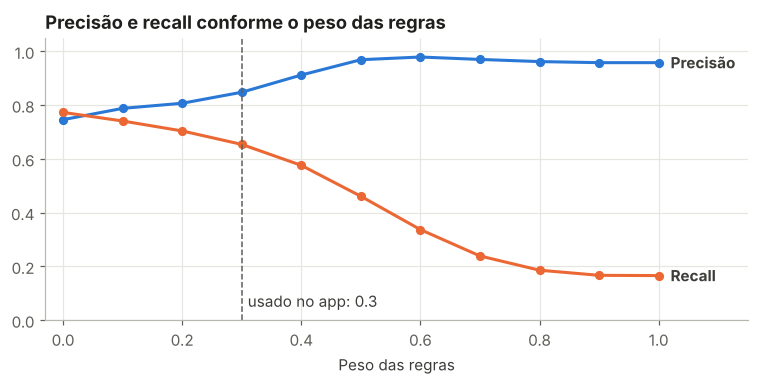

In [7]:
curva = pd.DataFrame(res["curva_peso_teste"]).T
curva.index = curva.index.astype(float)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(curva.index, curva["precisao"], color="#2a78d6", linewidth=2, marker="o", markersize=5)
ax.plot(curva.index, curva["recall"], color="#eb6834", linewidth=2, marker="o", markersize=5)
ax.text(1.02, curva["precisao"].iloc[-1], "Precisão", color="#3d3d3a", va="center", fontweight="bold")
ax.text(1.02, curva["recall"].iloc[-1], "Recall", color="#3d3d3a", va="center", fontweight="bold")
ax.axvline(res["peso_regras"], color="#5f5e5a", linewidth=1, linestyle="--")
ax.text(res["peso_regras"] + 0.01, 0.05, f"usado no app: {res['peso_regras']}", color="#3d3d3a")
ax.set_xlim(-0.03, 1.15)
ax.set_ylim(0, 1.05)
ax.set_xlabel("Peso das regras")
ax.set_title("Precisão e recall conforme o peso das regras", loc="left", fontweight="bold", color="#1f1f1d")
fig.tight_layout()

O app usa peso 0,3: perde um pouco de recall em troca de bem menos alarme falso. Para quem usa a ferramenta, ver um site verdadeiro marcado como golpe tira a confiança no resultado.

## O que o modelo olha

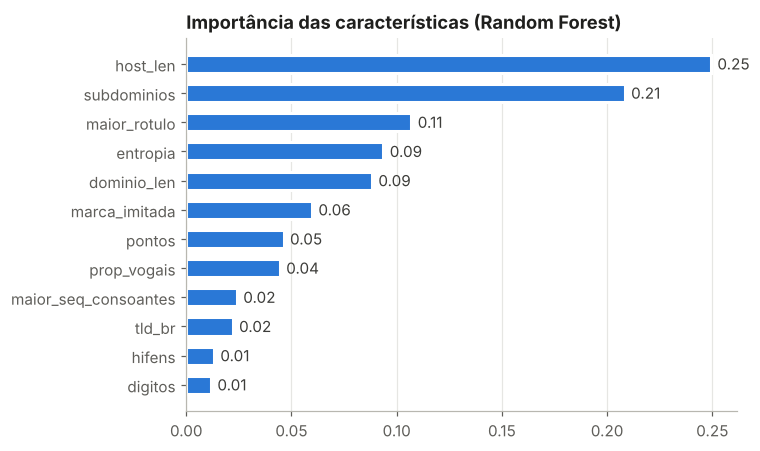

In [8]:
imp = pd.Series(res["importancia"]).head(12)[::-1]
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(imp.index, imp.values, color="#2a78d6", height=0.62, edgecolor="white", linewidth=2)
for i, v in enumerate(imp.values):
    ax.text(v + 0.003, i, f"{v:.2f}", va="center", color="#3d3d3a")
ax.set_title("Importância das características (Random Forest)", loc="left", fontweight="bold", color="#1f1f1d")
ax.grid(axis="y", visible=False)
fig.tight_layout()

## Limitações

- As legítimas são domínios populares. Sites pequenos e legítimos com nomes estranhos podem receber risco alto.
- Golpes em sites invadidos com domínio normal só são pegos pela parte de texto ou por regras de caminho.
- Os dados são de uma única coleta. O ideal é coletar por algumas semanas e testar em golpes mais novos que os do treino.